# 17 · Top employers, year by year

Who hired the most IT people each year, and who stayed on top?

**Method.** Same employer definition as notebook 05: company names normalised, corporate groups (FPT, Bosch, Vingroup ...) combined, one row per unique IT posting. Employers are ranked by postings within each calendar year. Two limits: only 44 % of 2021 postings name a company, and 2026 stops at October. A board's own employers dominate its ranking, so the ranking is drawn for all sources and for the two boards that run across the years, CareerBuilder (2021-2026) and LinkedIn (2023-2026).

In [1]:
import pandas as pd

from vnjobs.analysis import core as a
from vnjobs.analysis import employers_by_year as e

a.apply_style()
con = a.connect()
df = a.load_features(con)
rankings = {name: e.yearly_ranking(df, src) for name, src in e.SCOPES.items()}
for name, ranking in rankings.items():
    key = name.lower().replace(" ", "-")
    a.save_table(e.top_by_year(ranking), f"17-top-employers-{key}")
{n: sorted(r.year.unique()) for n, r in rankings.items()}

{'All sources': [np.int64(2021),
  np.int64(2022),
  np.int64(2023),
  np.int64(2024),
  np.int64(2025),
  np.int64(2026)],
 'CareerBuilder': [np.int64(2021),
  np.int64(2022),
  np.int64(2023),
  np.int64(2024),
  np.int64(2025),
  np.int64(2026)],
 'LinkedIn': [np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]}

## 1. All sources

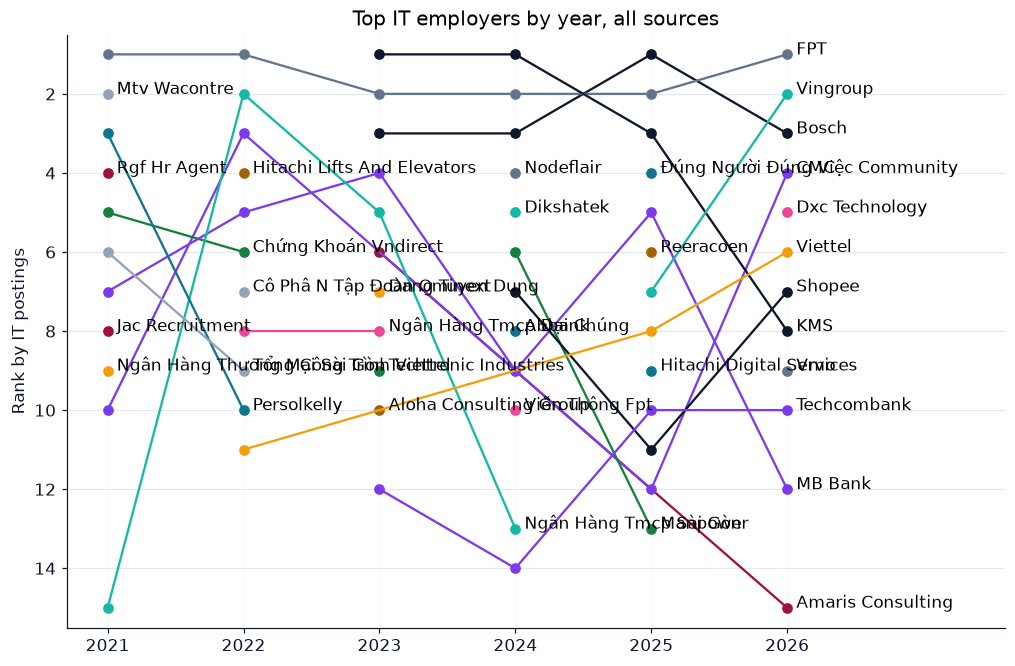

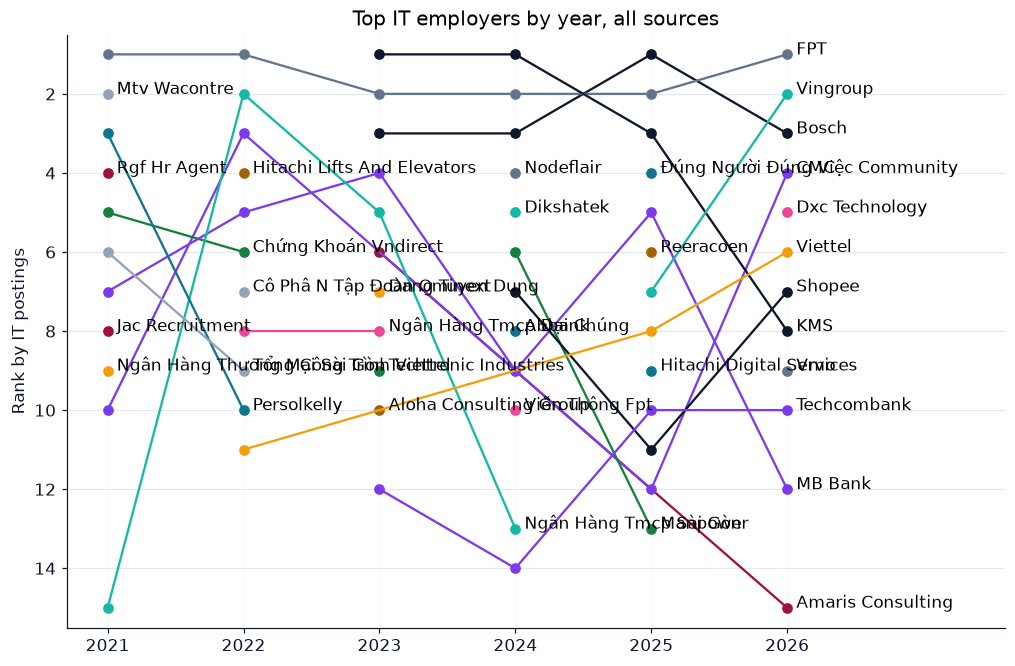

In [2]:
fig = e.chart_bump(rankings["All sources"], "Top IT employers by year, all sources")
a.save_chart(fig, "17-bump-all-sources")
fig

## 2. CareerBuilder

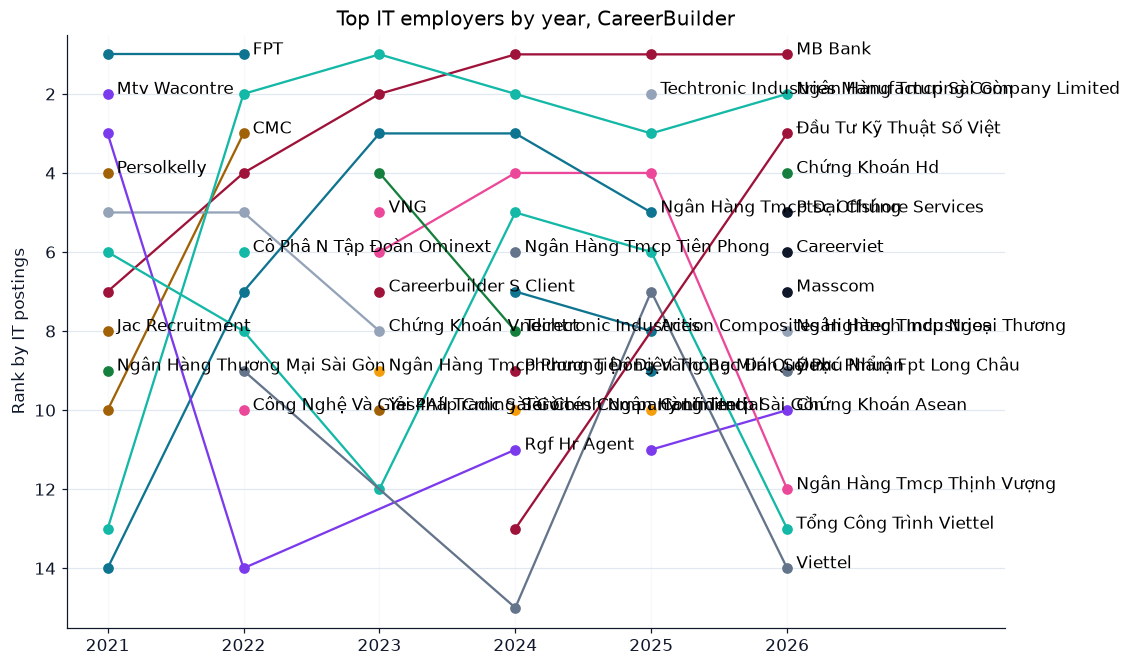

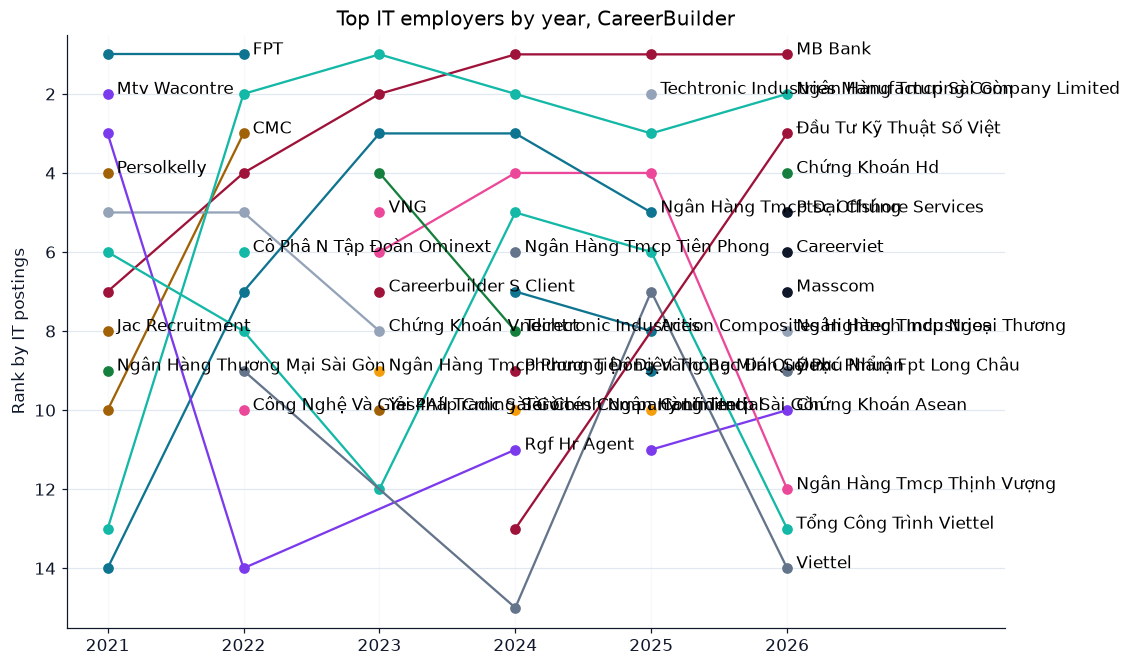

In [3]:
fig = e.chart_bump(rankings["CareerBuilder"], "Top IT employers by year, CareerBuilder")
a.save_chart(fig, "17-bump-careerbuilder")
fig

## 3. LinkedIn

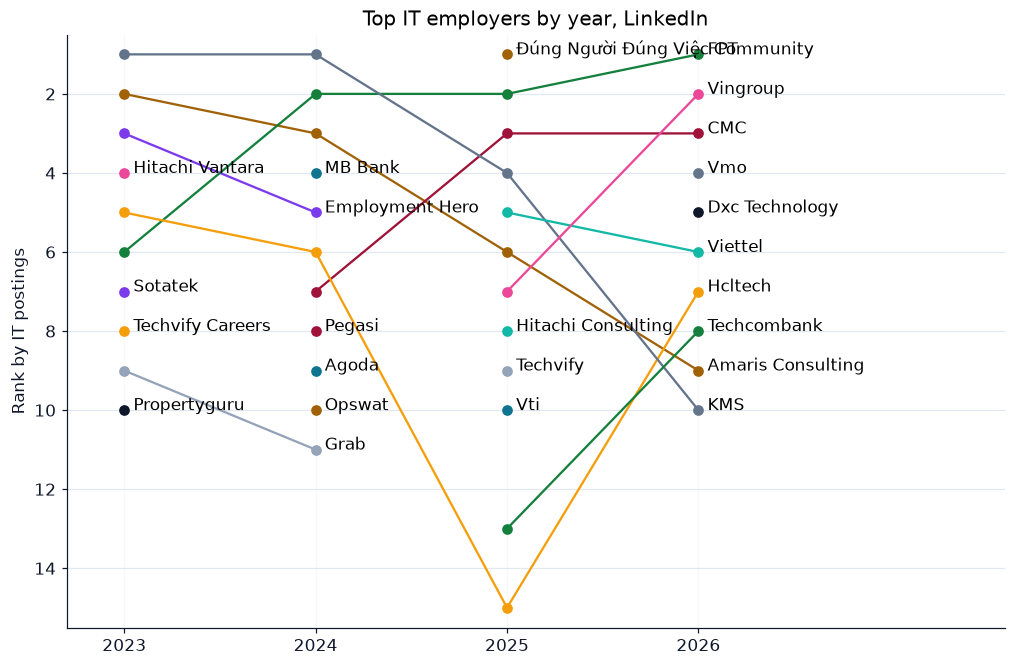

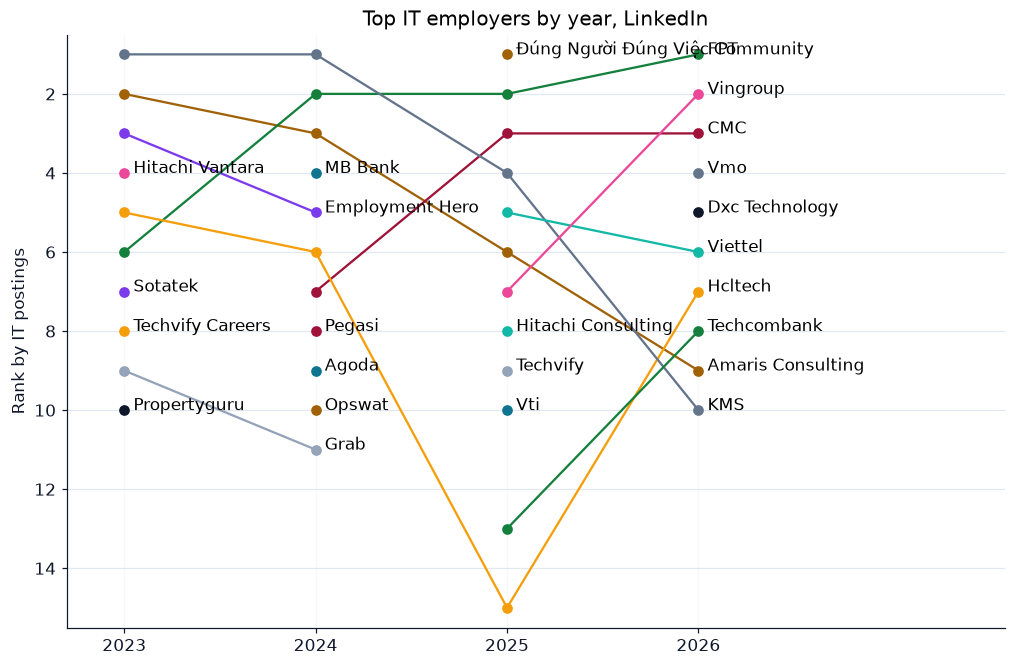

In [4]:
fig = e.chart_bump(rankings["LinkedIn"], "Top IT employers by year, LinkedIn")
a.save_chart(fig, "17-bump-linkedin")
fig

## 4. Who keeps returning to the top

In [5]:
summary = {name: e.years_in_top(r) for name, r in rankings.items()}
for name, frame in summary.items():
    a.save_table(frame, "17-years-in-top-" + name.lower().replace(" ", "-"))
summary["All sources"].head(12)

,company,years_in_top,best_rank
0,FPT,6,1
1,MB Bank,5,4
2,Bosch,4,1
3,KMS,4,1
4,CMC,3,3
5,Ngân Hàng Tmcp Sài Gòn,2,2
6,Vingroup,2,2
7,Persolkelly,2,3
8,Chứng Khoán Vndirect,2,5
9,Tổng Công Trình Viettel,2,6


In [6]:
summary["LinkedIn"].head(8)

,company,years_in_top,best_rank
0,FPT,4,1
1,KMS,4,1
2,Amaris Consulting,4,2
3,CMC,3,3
4,Hcltech,3,5
5,Vingroup,2,2
6,Employment Hero,2,3
7,Viettel,2,5


In [7]:
summary["CareerBuilder"].head(8)

,company,years_in_top,best_rank
0,MB Bank,6,1
1,Ngân Hàng Tmcp Sài Gòn,5,1
2,Ngân Hàng Tmcp Đại Chúng,4,3
3,Tổng Công Trình Viettel,4,5
4,Ngân Hàng Tmcp Thịnh Vượng,3,4
5,Chứng Khoán Vndirect,3,5
6,FPT,2,1
7,CMC,2,3


## 5. The leader's share each year

In [8]:
top = pd.concat([r[r["rank"] == 1].assign(scope=n) for n, r in rankings.items()])[
    ["scope", "year", "company", "postings", "share"]
]
a.save_table(top, "17-leader-by-year")
top

,scope,year,company,postings,share
304,All sources,2021,FPT,190,3.70
1681,All sources,2022,FPT,352,3.69
5892,All sources,2023,KMS,497,1.95
13606,All sources,2024,KMS,639,2.05
19696,All sources,2025,Bosch,637,1.85
29318,All sources,2026,FPT,821,2.25
290,CareerBuilder,2021,FPT,190,3.94
1625,CareerBuilder,2022,FPT,352,3.99
3868,CareerBuilder,2023,Ngân Hàng Tmcp Sài Gòn,193,2.81
5193,CareerBuilder,2024,MB Bank,149,3.45


## Findings

1. **FPT is the one employer in the top ten every year.** Six years out of six across all sources; first in 2021, 2022 and 2026. Its share of named postings fell from 3.7 % (2021 and 2022) to 2.25 % (2026), so even the leader holds a smaller slice.
2. **The leader changes hands.** KMS leads 2023 (1.95 %) and 2024 (2.05 %), Bosch leads 2025 (1.85 %). After them: MB Bank is in the top ten five years, KMS and Bosch four, CMC three. Vingroup climbs to second in 2026 on both all sources and LinkedIn.
3. **Who is on top depends on the board.** CareerBuilder is a bank list: MB Bank is in its top ten all six years and a Sài Gòn bank five, with FPT in two. LinkedIn is a software-house list: FPT, KMS and Amaris Consulting each four years. A single all-source ranking mixes the two, which is why the ranking is drawn for all three scopes.
4. **Caveats.** 2021 names a company on only 44 % of postings, and 2026 stops at October. Names are the normalised company key, title-cased, so a few read oddly. LinkedIn's first place in 2025, "Đúng Người Đúng Việc Community", looks like a recruitment community rather than an employer; it has not been checked and should not be quoted. The bump charts are for checking: labels collide, and the video version is rebuilt from the tables.

**What this notebook cannot say:** how many people an employer actually hired. Each posting is one vacancy ad, and an employer can repost one role many times.